# 07a. Prediction, Test-Year Evaluation, Fairness and Replication

This notebook is the **only place where the 2014 labels are used**. Notebooks 07b (imbalance, leakage, drift) and 07c (time series, A/B testing) follow it.

## Protocol, fixed before any test result was looked at

1. **Training data:** the 2013 presentations only. **Test data:** the 2014 presentations, evaluated once.
2. **Features:** the 18 features selected in notebook 04 (on 2013). A variant without the two socio-economic features (`edu_level`, `imd_order`) is evaluated for fairness.
3. **Models:** regularised logistic regression and gradient boosting, tuned by 5-fold cross-validation **grouped by student** on 2013. The cross-validated AUC picks the settings.
4. **Which model is primary:** the one with the higher cross-validated AUC, unless the two are within 0.003, in which case the simpler logistic model wins.
5. **Flagging policy for fairness and top-k results:** flag the 30% of students with the highest predicted risk (a capacity assumption, not tuned on labels).
6. **No model, feature or threshold choice is revisited after the test evaluation.** Anything that looks wrong in 2014 is reported as a finding, not fixed.
7. **Replication:** the 173 association rules from notebook 06 and the risk by engagement profile from notebook 05 are re-measured on 2014 with the same definitions.

In [1]:
import sys, json, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve
from statsmodels.stats.proportion import proportion_confint
import statsmodels.api as sm

sys.path.insert(0, "../src")
import items as it

RANDOM_STATE = 42
RAW, PROC, OUT = Path("../data/raw"), Path("../data/processed"), Path("../outputs")
FIG = OUT / "figures"
KEY = it.KEY

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 190); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
def savefig(fig, name): fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

feat = pd.read_csv(PROC / "oulad_features_day28.csv")
clus = pd.read_csv(PROC / "oulad_clusters_day28.csv")
fspec = json.loads((OUT / "feature_groups.json").read_text())
train = feat[feat.split == "train"].reset_index(drop=True)
test = feat[feat.split == "test"].reset_index(drop=True)
SEL_NUM, SEL_CAT = fspec["selected_numeric"], fspec["selected_categorical"]
SENS_FEATS = ["edu_level", "imd_order"]
NOSENS_NUM = [c for c in SEL_NUM if c not in SENS_FEATS]
y_tr, y_te = train.target_at_risk.values, test.target_at_risk.values
print(f"train {len(train):,} rows, at-risk {y_tr.mean():.3f} | test {len(test):,} rows (labels not looked at yet)")
print(f"{len(SEL_NUM)} numeric + {len(SEL_CAT)} categorical selected features; without socio-economic features: {len(NOSENS_NUM)} numeric")

train 11,818 rows, at-risk 0.444 | test 15,735 rows (labels not looked at yet)
17 numeric + 1 categorical selected features; without socio-economic features: 15 numeric


## 1. Tuning on the training years (grouped cross-validation, 2013 only)

In [2]:
cv = GroupKFold(n_splits=5)
folds = list(cv.split(train, groups=train.id_student))

def make_pipe(num_cols, cat_cols, kind, **p):
    scaled = kind == "logit"
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]) if scaled else "passthrough"
    parts = [("num", num, list(num_cols))] + ([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat_cols))] if cat_cols else [])
    if scaled:
        est = LogisticRegression(max_iter=5000, C=p.get("C", 1.0))
    else:
        est = HistGradientBoostingClassifier(max_depth=p.get("depth", 3), learning_rate=p.get("lr", 0.05), max_iter=p.get("iters", 200),
                                             l2_regularization=p.get("l2", 1.0), min_samples_leaf=p.get("leaf", 20), random_state=RANDOM_STATE)
    return Pipeline([("pre", ColumnTransformer(parts)), ("m", est)])

def cv_oof(num_cols, cat_cols, kind, data=None, **p):
    data = train if data is None else data
    X = data[list(num_cols) + list(cat_cols)]; y = data.target_at_risk.values; oof = np.zeros(len(data)); aucs = []
    for tr, va in folds:
        m = make_pipe(num_cols, cat_cols, kind, **p).fit(X.iloc[tr], y[tr]); oof[va] = m.predict_proba(X.iloc[va])[:, 1]; aucs.append(roc_auc_score(y[va], oof[va]))
    return oof, np.array(aucs)

rows = []
for C in (0.01, 0.03, 0.1, 0.3, 1, 3):
    oof, a = cv_oof(SEL_NUM, SEL_CAT, "logit", C=C); rows.append(dict(model="logit", setting=f"C={C}", cv_auc=a.mean(), cv_sd=a.std(), brier=brier_score_loss(y_tr, oof), params=dict(C=C)))
HGB_GRID = [dict(depth=2, lr=0.05, iters=200, l2=1.0, leaf=20), dict(depth=3, lr=0.05, iters=200, l2=1.0, leaf=20), dict(depth=3, lr=0.03, iters=400, l2=1.0, leaf=20),
            dict(depth=4, lr=0.03, iters=300, l2=3.0, leaf=40), dict(depth=3, lr=0.1, iters=100, l2=1.0, leaf=20), dict(depth=2, lr=0.1, iters=300, l2=1.0, leaf=20),
            dict(depth=4, lr=0.05, iters=150, l2=3.0, leaf=40), dict(depth=6, lr=0.03, iters=200, l2=5.0, leaf=60)]
for g in HGB_GRID:
    oof, a = cv_oof(SEL_NUM, SEL_CAT, "hgb", **g); rows.append(dict(model="hgb", setting=str(g), cv_auc=a.mean(), cv_sd=a.std(), brier=brier_score_loss(y_tr, oof), params=g))
tune = pd.DataFrame(rows)
best_l = tune[tune.model == "logit"].sort_values("cv_auc", ascending=False).iloc[0]; best_h = tune[tune.model == "hgb"].sort_values("cv_auc", ascending=False).iloc[0]
display(tune.drop(columns="params").sort_values(["model", "cv_auc"], ascending=[True, False]).reset_index(drop=True))
PRIMARY = "logit" if best_l.cv_auc >= best_h.cv_auc - 0.003 else "hgb"
print(f"best logistic: {best_l.setting} (CV AUC {best_l.cv_auc:.4f}) | best boosting: {best_h.setting} (CV AUC {best_h.cv_auc:.4f})")
print(f"==> primary model by the pre-stated rule: {PRIMARY}")

,model,setting,cv_auc,cv_sd,brier
0,hgb,"{'depth': 4, 'lr': 0.03, 'iters': 300, 'l2': 3.0, 'leaf': 40}",0.793,0.010,0.182
1,hgb,"{'depth': 3, 'lr': 0.03, 'iters': 400, 'l2': 1.0, 'leaf': 20}",0.793,0.010,0.182
2,hgb,"{'depth': 4, 'lr': 0.05, 'iters': 150, 'l2': 3.0, 'leaf': 40}",0.793,0.009,0.182
3,hgb,"{'depth': 3, 'lr': 0.05, 'iters': 200, 'l2': 1.0, 'leaf': 20}",0.793,0.009,0.182
4,hgb,"{'depth': 3, 'lr': 0.1, 'iters': 100, 'l2': 1.0, 'leaf': 20}",0.792,0.009,0.182
5,hgb,"{'depth': 6, 'lr': 0.03, 'iters': 200, 'l2': 5.0, 'leaf': 60}",0.792,0.009,0.183
6,hgb,"{'depth': 2, 'lr': 0.1, 'iters': 300, 'l2': 1.0, 'leaf': 20}",0.792,0.010,0.182
7,hgb,"{'depth': 2, 'lr': 0.05, 'iters': 200, 'l2': 1.0, 'leaf': 20}",0.791,0.010,0.183
8,logit,C=0.1,0.784,0.008,0.186
9,logit,C=0.3,0.784,0.009,0.186


best logistic: C=0.1 (CV AUC 0.7838) | best boosting: {'depth': 4, 'lr': 0.03, 'iters': 300, 'l2': 3.0, 'leaf': 40} (CV AUC 0.7928)
==> primary model by the pre-stated rule: hgb


**Observed.** Gradient boosting reaches a cross-validated AUC of 0.793 on 2013; several settings are tied within 0.002, so the result does not hinge on a lucky configuration. Logistic regression reaches 0.784 for every penalty from C = 0.03 to 3. Boosting is also slightly better calibrated in cross-validation (Brier 0.182 vs 0.186). The gap of 0.009 exceeds the 0.003 margin set in the protocol, so **gradient boosting is the primary model**.

### 1.1 Does a module interaction help? (the engagement effect differs a lot between modules)

In [3]:
ENG = ["eng_pct_clicks", "eng_pct_poststart_days", "eng_pct_sites"]
MODS = sorted(train.code_module.unique())
def add_inter(df):
    df = df.copy()
    for m in MODS:
        for f in ENG: df[f"{f}__x__{m}"] = df[f] * (df.code_module == m)
    return df
train_i, test_i = add_inter(train), add_inter(test)
INTER = [f"{f}__x__{m}" for m in MODS for f in ENG]
base_oof, base_a = cv_oof(SEL_NUM, SEL_CAT, "logit", C=best_l.params["C"])
int_oof, int_a = cv_oof(SEL_NUM + INTER, SEL_CAT, "logit", data=train_i, C=best_l.params["C"])
hgb_oof, hgb_a = cv_oof(SEL_NUM, SEL_CAT, "hgb", **best_h.params)
inter = pd.DataFrame({"logistic": [base_a.mean(), base_a.std()], "logistic + module x engagement": [int_a.mean(), int_a.std()], "gradient boosting": [hgb_a.mean(), hgb_a.std()]}, index=["cv_auc", "cv_sd"]).T
display(inter)
print("paired fold differences (interaction minus plain logistic):", np.round(int_a - base_a, 4), "| mean", round((int_a - base_a).mean(), 4))

,cv_auc,cv_sd
logistic,0.784,0.008
logistic + module x engagement,0.786,0.008
gradient boosting,0.793,0.010


paired fold differences (interaction minus plain logistic): [-0.0002  0.0043  0.0031  0.0006  0.0028] | mean 0.0021


**Observed.** Adding module-by-engagement interactions to the logistic model raises the cross-validated AUC by only 0.002 (0.784 to 0.786; fold differences from -0.0002 to +0.004).
**Why it matters.** The engagement effect differs a lot between modules (odds ratio 11.7 in EEE, 1.6 in GGG), but the module-relative features and the module term already absorb most of that. The interaction model is not used further.

## 2. Final fit and the single test-year evaluation (2014)

In [4]:
Xcols = SEL_NUM + SEL_CAT
final_l = make_pipe(SEL_NUM, SEL_CAT, "logit", **best_l.params).fit(train[Xcols], y_tr)
final_h = make_pipe(SEL_NUM, SEL_CAT, "hgb", **best_h.params).fit(train[Xcols], y_tr)
final_i = make_pipe(SEL_NUM + INTER, SEL_CAT, "logit", **best_l.params).fit(train_i[SEL_NUM + INTER + SEL_CAT], y_tr)
test["p_logit"] = final_l.predict_proba(test[Xcols])[:, 1]
test["p_hgb"] = final_h.predict_proba(test[Xcols])[:, 1]
test["p_inter"] = final_i.predict_proba(test_i[SEL_NUM + INTER + SEL_CAT])[:, 1]
test["p_primary"] = test["p_" + PRIMARY]
print("test predictions made. primary model:", PRIMARY)

def topk(y, p, frac):
    k = int(np.ceil(frac * len(y))); idx = np.argsort(-p)[:k]
    return dict(precision=y[idx].mean(), recall=y[idx].sum() / y.sum(), lift=y[idx].mean() / y.mean())

def evaluate(y, p):
    sl = sm.Logit(y, sm.add_constant(np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6))))).fit(disp=0)
    return dict(auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p), brier=brier_score_loss(y, p), log_loss=log_loss(y, p),
                mean_pred=p.mean(), observed=y.mean(), calib_intercept=sl.params[0], calib_slope=sl.params[1],
                prec_top10=topk(y, p, .10)["precision"], prec_top30=topk(y, p, .30)["precision"], recall_top30=topk(y, p, .30)["recall"], lift_top30=topk(y, p, .30)["lift"])

rows = {}
for name, col in [("logistic (selected 18)", "p_logit"), ("gradient boosting (selected 18)", "p_hgb"), ("logistic + module interactions", "p_inter")]:
    rows[name] = evaluate(y_te, test[col].values)
res = pd.DataFrame(rows).T
res.to_csv(OUT / "model_test_results.csv")
res_show = res[["auc", "pr_auc", "brier", "calib_intercept", "calib_slope", "mean_pred", "observed", "prec_top30", "recall_top30", "lift_top30"]]
display(res_show)

# Simple baselines, scored on ranking quality only (they are scores, not probabilities). All use training-year information only.
mod_rate = train.groupby("code_module").target_at_risk.mean()
sign = np.sign(np.corrcoef(train.eng_pct_clicks, y_tr)[0, 1])
base_scores = {"module prior rate": test.code_module.map(mod_rate).fillna(y_tr.mean()).values,
               "engagement rank within module": sign * test.eng_pct_clicks.values,        # sign is negative: less engagement, more risk
               "missed an early assessment (yes/no)": (test.submit_rate_early.fillna(1) < 1).astype(float).values,
               "early score rank (low = risky)": -test.score_pct_mean.fillna(test.score_pct_mean.median()).values}
bl = pd.DataFrame({k: {"auc": roc_auc_score(y_te, v), "pr_auc": average_precision_score(y_te, v), "recall_top30": topk(y_te, v + np.random.RandomState(0).normal(0, 1e-9, len(v)), .30)["recall"]} for k, v in base_scores.items()}).T
bl.loc["gradient boosting (selected 18)"] = [res.loc["gradient boosting (selected 18)", c] for c in ("auc", "pr_auc", "recall_top30")]
bl.loc["logistic (selected 18)"] = [res.loc["logistic (selected 18)", c] for c in ("auc", "pr_auc", "recall_top30")]
bl.to_csv(OUT / "baselines_test_results.csv"); bl

test predictions made. primary model: hgb


,auc,pr_auc,brier,calib_intercept,calib_slope,mean_pred,observed,prec_top30,recall_top30,lift_top30
logistic (selected 18),0.776,0.741,0.189,0.040,1.041,0.435,0.440,0.753,0.514,1.713
gradient boosting (selected 18),0.780,0.751,0.187,-0.007,1.029,0.443,0.440,0.757,0.516,1.721
logistic + module interactions,0.778,0.744,0.188,0.006,1.034,0.440,0.440,0.755,0.515,1.717


,auc,pr_auc,recall_top30
module prior rate,0.551,0.471,0.317
engagement rank within module,0.696,0.652,0.446
missed an early assessment (yes/no),0.589,0.524,0.381
early score rank (low = risky),0.638,0.577,0.371
gradient boosting (selected 18),0.780,0.751,0.516
logistic (selected 18),0.776,0.741,0.514


**Observed (2014 test year, evaluated once).** The primary model reaches **AUC 0.780** and PR-AUC 0.751; logistic regression 0.776 and the interaction model 0.778. The cross-validated AUC on 2013 was 0.793 (logistic 0.784), so the out-of-time result is about 0.013 lower, which is what a new year plus mild optimism from selecting features on the training rows would predict.
**Calibration is very good**: mean predicted risk 44.3% against 44.0% observed, calibration intercept -0.007 and slope 1.03 (a perfect model has 0 and 1).
**Flagging the 30% highest-risk students** gives a precision of 75.7% and reaches 51.6% of all at-risk students (lift 1.72).
**Baselines** (ranking quality only): module prior 0.55, missed an early assessment 0.59, early score rank 0.64 and engagement rank within the module 0.70. The model adds about 0.08 AUC over the best single baseline.

In [5]:
rng = np.random.RandomState(RANDOM_STATE)
B = 1000; boot_idx = [rng.randint(0, len(y_te), len(y_te)) for _ in range(B)]
def boot_both(p):
    a = np.array([roc_auc_score(y_te[i], p[i]) for i in boot_idx]); q = np.array([average_precision_score(y_te[i], p[i]) for i in boot_idx])
    return np.percentile(a, [2.5, 97.5]), np.percentile(q, [2.5, 97.5])
rows = {}
for m, c in [("logistic", "p_logit"), ("gradient boosting", "p_hgb"), ("logistic + interactions", "p_inter")]:
    (a_lo, a_hi), (q_lo, q_hi) = boot_both(test[c].values)
    rows[m] = {"AUC": roc_auc_score(y_te, test[c]), "AUC 2.5%": a_lo, "AUC 97.5%": a_hi, "PR-AUC": average_precision_score(y_te, test[c]), "PR-AUC 2.5%": q_lo, "PR-AUC 97.5%": q_hi}
ci = pd.DataFrame(rows).T
print(f"cross-validated AUC on 2013: logistic {base_a.mean():.3f}, boosting {hgb_a.mean():.3f}, interactions {int_a.mean():.3f}")
display(ci)

cross-validated AUC on 2013: logistic 0.784, boosting 0.793, interactions 0.786


,AUC,AUC 2.5%,AUC 97.5%,PR-AUC,PR-AUC 2.5%,PR-AUC 97.5%
logistic,0.776,0.768,0.782,0.741,0.731,0.751
gradient boosting,0.780,0.773,0.786,0.751,0.741,0.761
logistic + interactions,0.778,0.771,0.785,0.744,0.734,0.755


**Observed.** The 95% bootstrap interval is 0.773 to 0.786 for the primary model (PR-AUC 0.741 to 0.761). The intervals of the three models overlap heavily; boosting is about 0.004 better than logistic regression.
**Why it matters.** The simpler logistic model loses very little (0.004 AUC), so it remains a defensible choice when transparency matters more than the last fraction of accuracy.

In [6]:
# Where does the primary model work and where not? per module, per presentation, and without returning students
def seg(df, mask, label):
    d = df[mask]; return dict(segment=label, n=len(d), at_risk_rate=d.target_at_risk.mean(), auc=roc_auc_score(d.target_at_risk, d.p_primary), mean_pred=d.p_primary.mean())
returning = test.id_student.isin(train.id_student)
rows = [seg(test, test.code_module == m, f"module {m}") for m in sorted(test.code_module.unique())]
rows += [seg(test, test.code_presentation == p, f"presentation {p}") for p in sorted(test.code_presentation.unique())]
rows += [seg(test, ~returning, "students new in 2014"), seg(test, returning, "returning students"), seg(test, test.code_module != "CCC", "all modules except CCC (seen in 2013)")]
segs = pd.DataFrame(rows).set_index("segment")
rng2 = np.random.RandomState(1)
def seg_ci(mask):
    d = test[mask]; y_, p_ = d.target_at_risk.values, d.p_primary.values; b = [roc_auc_score(y_[i], p_[i]) for i in (rng2.randint(0, len(d), len(d)) for _ in range(300))]; return np.percentile(b, [2.5, 97.5])
cis = [seg_ci(test.code_module == m) for m in sorted(test.code_module.unique())] + [seg_ci(test.code_presentation == p) for p in sorted(test.code_presentation.unique())] + [seg_ci(~returning), seg_ci(returning), seg_ci(test.code_module != "CCC")]
segs["auc_lo"], segs["auc_hi"] = [c[0] for c in cis], [c[1] for c in cis]
segs.to_csv(OUT / "model_test_segments.csv"); segs

,n,at_risk_rate,auc,mean_pred,auc_lo,auc_hi
segment,,,,,,
module AAA,348,0.273,0.704,0.289,0.638,0.770
module BBB,3069,0.388,0.736,0.400,0.714,0.755
module CCC,3523,0.524,0.810,0.521,0.797,0.822
module DDD,2493,0.490,0.800,0.469,0.784,0.817
module EEE,1626,0.360,0.775,0.359,0.751,0.799
module FFF,3162,0.440,0.788,0.451,0.772,0.800
module GGG,1514,0.391,0.688,0.411,0.665,0.714
presentation 2014B,6516,0.485,0.786,0.467,0.776,0.796
presentation 2014J,9219,0.408,0.772,0.425,0.763,0.782


**Observed (primary model).** AUC ranges from 0.69 in GGG and 0.70 in AAA (only 348 students, interval 0.64 to 0.77) to 0.80 in DDD and 0.81 in CCC. **Module CCC, which the model never saw in 2013, is predicted best** (AUC 0.810, interval 0.797 to 0.822; mean predicted 52.1% vs 52.4% observed). That is better than the 0.71 to 0.74 expected from the leave-one-module-out check in notebook 04, so the module-relative features transferred even better than feared. Without CCC the AUC is 0.767.
February-start presentations are predicted slightly better (0.786) than October-start ones (0.772). Returning students (0.768) and new students (0.775) are predicted equally well within noise, and their risk is predicted correctly (returning students: 60.4% predicted, 60.9% observed), so the overlap of people between the years does not inflate the result.
**Why it matters.** The weak modules are the ones flagged earlier: GGG has no early assessments and a weak engagement signal, AAA is small. A single overall AUC hides a spread of 0.12 between modules.

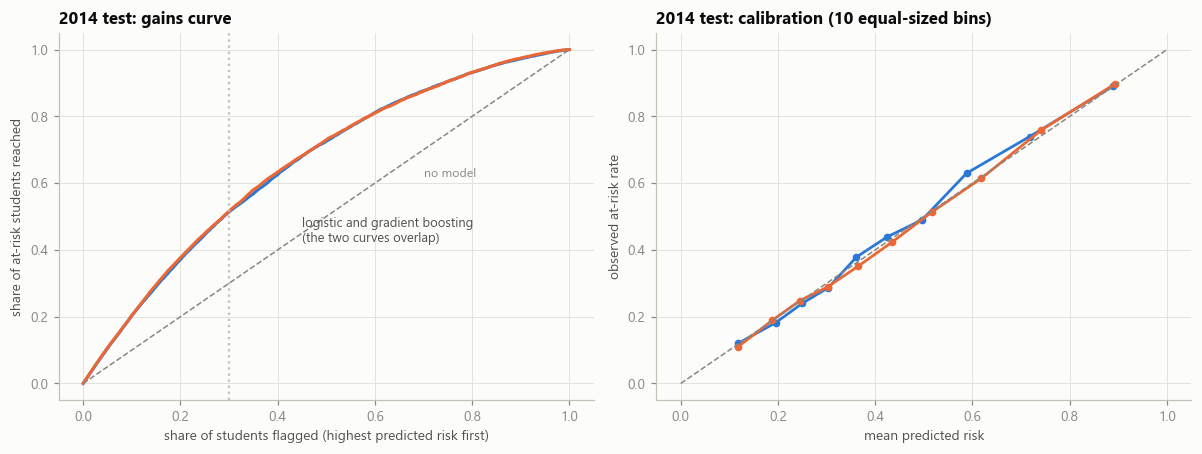

In [7]:
# Gains curve, reliability plot and ranking quality
def gains(y, p):
    o = np.argsort(-p); cum = np.cumsum(y[o]) / y.sum(); x = np.arange(1, len(y) + 1) / len(y); return x, cum
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
for col, lab, c in [("p_logit", "logistic", C1), ("p_hgb", "gradient boosting", C2)]:
    x, g = gains(y_te, test[col].values); ax.plot(x, g, color=c, linewidth=2)
ax.text(0.45, 0.50, "logistic and gradient boosting\n(the two curves overlap)", color=INK2, fontsize=8.5, ha="left", va="top")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1); ax.text(0.7, 0.62, "no model", color=MUTED, fontsize=8)
ax.axvline(0.30, color=AXIS, linestyle=":"); ax.set_xlabel("share of students flagged (highest predicted risk first)"); ax.set_ylabel("share of at-risk students reached")
ax.set_title("2014 test: gains curve")
ax = axes[1]
for col, lab, c in [("p_logit", "logistic", C1), ("p_hgb", "gradient boosting", C2)]:
    fo, mp = calibration_curve(y_te, test[col], n_bins=10, strategy="quantile"); ax.plot(mp, fo, "-o", color=c, linewidth=1.8, markersize=4)
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1); ax.set_xlabel("mean predicted risk"); ax.set_ylabel("observed at-risk rate"); ax.set_title("2014 test: calibration (10 equal-sized bins)")
fig.tight_layout(); savefig(fig, "07a_gains_calibration.png"); plt.show()

**Observed.** The gains curve lies clearly above the diagonal everywhere, and the two models are indistinguishable. Both follow the diagonal of the reliability plot closely; the logistic model is slightly too low in the middle bins (about 0.35 to 0.65), the boosting model is near-perfect.

## 3. Fairness: who is flagged, and who is missed?

Policy fixed in advance: flag the 30% of students with the highest predicted risk. Error rates are reported for each group on the 2014 test year.

In [8]:
cats_te = it.categories(test, clus, it.fit_item_spec(train))
test["_flag"] = test.p_primary >= np.quantile(test.p_primary, 0.70)
print(f"flag rule: top 30% of predicted risk (cut at {np.quantile(test.p_primary, .70):.3f}); overall: precision {y_te[test._flag].mean():.3f}, recall {y_te[test._flag].sum() / y_te.sum():.3f}")

def group_table(col, pred_col="p_primary", flag=None, order=None):
    flag = test["_flag"] if flag is None else flag
    rows = []
    for lv in (order or sorted(cats_te[col].dropna().unique())):
        m = (cats_te[col] == lv).values; y_ = y_te[m]; f_ = flag.values[m]; p_ = test.loc[m, pred_col].values
        tp, fp, fn, tn = ((f_ & (y_ == 1)).sum(), (f_ & (y_ == 0)).sum(), (~f_ & (y_ == 1)).sum(), (~f_ & (y_ == 0)).sum())
        lo, hi = proportion_confint(tp, tp + fn, method="wilson") if tp + fn else (np.nan, np.nan)
        rows.append(dict(group=f"{col}={lv}", n=int(m.sum()), at_risk_rate=y_.mean(), flagged=f_.mean(), recall_TPR=tp / (tp + fn), tpr_lo=lo, tpr_hi=hi, false_pos_rate=fp / (fp + tn),
                         precision=tp / max(tp + fp, 1), auc=roc_auc_score(y_, p_), mean_pred=p_.mean()))
    return pd.DataFrame(rows).set_index("group")
GROUPS = {"Deprivation": ["Deprived", "Middle", "Affluent", "Unknown"], "Education": ["BelowALevel", "ALevel", "HEplus"], "Disability": ["Yes", "No"], "Gender": ["F", "M"], "Age": ["Under35", "35plus"]}
fair = pd.concat([group_table(c, order=o) for c, o in GROUPS.items()])
fair.to_csv(OUT / "fairness_primary_model.csv"); fair

flag rule: top 30% of predicted risk (cut at 0.563); overall: precision 0.757, recall 0.516


,n,at_risk_rate,flagged,recall_TPR,tpr_lo,tpr_hi,false_pos_rate,precision,auc,mean_pred
group,,,,,,,,,,
Deprivation=Deprived,4773,0.514,0.395,0.587,0.567,0.606,0.191,0.765,0.770,0.513
Deprivation=Middle,6232,0.434,0.288,0.503,0.484,0.522,0.122,0.759,0.778,0.435
Deprivation=Affluent,4119,0.383,0.234,0.450,0.426,0.475,0.099,0.739,0.779,0.391
Deprivation=Unknown,611,0.296,0.136,0.343,0.277,0.414,0.049,0.747,0.737,0.316
Education=BelowALevel,6100,0.520,0.401,0.594,0.576,0.611,0.193,0.769,0.774,0.523
Education=ALevel,6926,0.402,0.244,0.453,0.435,0.472,0.103,0.748,0.773,0.399
Education=HEplus,2709,0.357,0.217,0.445,0.414,0.476,0.090,0.733,0.768,0.373
Disability=Yes,1491,0.541,0.374,0.550,0.515,0.584,0.166,0.795,0.773,0.491
Disability=No,14244,0.429,0.292,0.512,0.500,0.525,0.127,0.752,0.779,0.438


In [9]:
# Does removing the socio-economic features (education, deprivation) change who is flagged?
nos = make_pipe(NOSENS_NUM, SEL_CAT, "logit" if PRIMARY == "logit" else "hgb", **(best_l.params if PRIMARY == "logit" else best_h.params)).fit(train[NOSENS_NUM + SEL_CAT], y_tr)
test["p_nosens"] = nos.predict_proba(test[NOSENS_NUM + SEL_CAT])[:, 1]
flag_ns = test.p_nosens >= np.quantile(test.p_nosens, 0.70)
cmp_rows = []
for c, o in GROUPS.items():
    a = group_table(c, "p_primary", order=o); b = group_table(c, "p_nosens", flag_ns, order=o)
    for g in a.index:
        cmp_rows.append(dict(group=g, n=a.loc[g, "n"], at_risk_rate=a.loc[g, "at_risk_rate"], recall_with=a.loc[g, "recall_TPR"], recall_without=b.loc[g, "recall_TPR"],
                             fpr_with=a.loc[g, "false_pos_rate"], fpr_without=b.loc[g, "false_pos_rate"], flagged_with=a.loc[g, "flagged"], flagged_without=b.loc[g, "flagged"]))
cmp_df = pd.DataFrame(cmp_rows).set_index("group")
print(f"AUC on 2014 with the socio-economic features {roc_auc_score(y_te, test.p_primary):.4f} | without {roc_auc_score(y_te, test.p_nosens):.4f}")
display(cmp_df)
print("largest recall gap between groups of one variable (with vs without):")
gaps = []
for c, o in GROUPS.items():
    idx = [f"{c}={g}" for g in o if f"{c}={g}" in cmp_df.index and cmp_df.loc[f"{c}={g}", "n"] >= 200]
    gaps.append(dict(variable=c, gap_with=cmp_df.loc[idx, "recall_with"].max() - cmp_df.loc[idx, "recall_with"].min(), gap_without=cmp_df.loc[idx, "recall_without"].max() - cmp_df.loc[idx, "recall_without"].min()))
pd.DataFrame(gaps).set_index("variable")

AUC on 2014 with the socio-economic features 0.7798 | without 0.7707


,n,at_risk_rate,recall_with,recall_without,fpr_with,fpr_without,flagged_with,flagged_without
group,,,,,,,,
Deprivation=Deprived,4773,0.514,0.587,0.518,0.191,0.134,0.395,0.331
Deprivation=Middle,6232,0.434,0.503,0.512,0.122,0.132,0.288,0.297
Deprivation=Affluent,4119,0.383,0.450,0.505,0.099,0.130,0.234,0.274
Deprivation=Unknown,611,0.296,0.343,0.519,0.049,0.163,0.136,0.268
Education=BelowALevel,6100,0.520,0.594,0.502,0.193,0.120,0.401,0.319
Education=ALevel,6926,0.402,0.453,0.515,0.103,0.138,0.244,0.290
Education=HEplus,2709,0.357,0.445,0.540,0.090,0.144,0.217,0.285
Disability=Yes,1491,0.541,0.550,0.526,0.166,0.145,0.374,0.351
Disability=No,14244,0.429,0.512,0.511,0.127,0.132,0.292,0.295


largest recall gap between groups of one variable (with vs without):


,gap_with,gap_without
variable,,
Deprivation,0.244,0.015
Education,0.149,0.038
Disability,0.038,0.015
Gender,0.123,0.138
Age,0.054,0.057


**Observed (flagging the top 30%).** Recall differs strongly between groups: deprived students 58.7% vs affluent 45.0% (unknown 34.3%), education below A level 59.4% vs higher education 44.5%, men 56.6% vs women 44.2%, under 35 53.1% vs 35 and over 47.7%, and disability 55.0% vs 51.2% (intervals overlap). False-positive rates follow the same pattern (deprived 19.1% vs affluent 9.9%, below A level 19.3% vs higher education 9.0%). Precision is similar everywhere (73% to 80%), and predicted risk matches observed risk within each group except for disabled students, whose risk is under-predicted by 5 points (49.1% predicted, 54.1% observed).
**Why it matters.** The model is calibrated inside each group, but groups with a higher base rate (deprived 51.4% vs affluent 38.3%) are flagged more often, which raises both the share of their at-risk students that is found and the share of their not-at-risk students that is flagged by mistake. Whether that is acceptable depends on the intervention: for low-cost supportive outreach, reaching more of the disadvantaged is partly the point; if contact is costly or feels like a label, the doubled false-positive rate is a burden.
**Without the two socio-economic features** (education and deprivation) the AUC falls from 0.780 to 0.771 and the error rates almost equalise across deprivation and education groups: recall 0.52, 0.51, 0.51 and 0.52 across deprivation groups (gap 0.244 to 0.015) and a gap of 0.038 across education groups (was 0.149); false-positive rates 13.4% (deprived) vs 13.0% (affluent). The gender gap is unchanged (0.12 to 0.14) because gender is not a feature.
**Recommendation.** Use the model *without* the socio-economic features to build the alert list (a cost of 0.009 AUC for equal error rates across deprivation and education), and let advisers use deprivation information separately to decide how much support to offer. This is a policy choice for the university, not a technical one.

### 3.1 Why is the model less accurate for women? (gender is not a feature)

In [10]:
rows = []
for m in sorted(test.code_module.unique()):
    r_ = {"module": m}
    for g in ("F", "M"):
        mask = ((test.code_module == m) & (cats_te.Gender == g)).values
        r_[f"n_{g}"] = int(mask.sum()); r_[f"at_risk_{g}"] = y_te[mask].mean(); r_[f"auc_{g}"] = roc_auc_score(y_te[mask], test.p_primary.values[mask])
    r_["auc_gap_M_minus_F"] = r_["auc_M"] - r_["auc_F"]; rows.append(r_)
gm = pd.DataFrame(rows).set_index("module"); display(gm)
print(f"overall AUC: women {roc_auc_score(y_te[(cats_te.Gender == 'F').values], test.p_primary[(cats_te.Gender == 'F').values]):.3f}, men {roc_auc_score(y_te[(cats_te.Gender == 'M').values], test.p_primary[(cats_te.Gender == 'M').values]):.3f}")
fm = {"engagement rank": "eng_pct_clicks", "early score rank": "score_pct_mean", "early submission rate": "submit_rate_early", "days before deadline": "days_before_due_mean", "prior education": "edu_level"}
rows = {}
for lab, c in fm.items():
    rows[lab] = {g: abs(2 * roc_auc_score(y_te[(cats_te.Gender == g).values & test[c].notna().values], test.loc[(cats_te.Gender == g).values & test[c].notna().values, c]) - 1) for g in ("F", "M")}
display(pd.DataFrame(rows).T.rename(columns={"F": "separation (women)", "M": "separation (men)"}))

,n_F,at_risk_F,auc_F,n_M,at_risk_M,auc_M,auc_gap_M_minus_F
module,,,,,,,
AAA,151,0.305,0.657,197,0.249,0.753,0.095
BBB,2703,0.384,0.742,366,0.415,0.688,-0.054
CCC,853,0.468,0.799,2670,0.542,0.812,0.012
DDD,983,0.510,0.784,1510,0.477,0.811,0.028
EEE,196,0.357,0.727,1430,0.360,0.782,0.055
FFF,569,0.409,0.774,2593,0.447,0.790,0.017
GGG,1216,0.384,0.696,298,0.419,0.660,-0.036


overall AUC: women 0.751, men 0.797


,separation (women),separation (men)
engagement rank,0.348,0.420
early score rank,0.378,0.414
early submission rate,0.188,0.226
days before deadline,0.203,0.240
prior education,0.132,0.155


**Observed.** The overall AUC is 0.751 for women and 0.797 for men, but most of that gap is **module mix**: women are 88% of the students in BBB and 80% in GGG, the two modules where the model works worst (AUC 0.74 and 0.69), while men dominate CCC, DDD and FFF, where it works best. Inside a module the gap is small and goes both ways (BBB -0.054 and GGG -0.036 against women, CCC +0.012, DDD +0.028, FFF +0.017, EEE +0.055 and AAA +0.095 in favour of men). The pooled differences in how well engagement and early scores separate the groups (for example 0.35 vs 0.42 for engagement) reflect the same mix.
**Action.** Do not describe this as gender bias in the model; report it as a module-composition effect and keep monitoring per module.

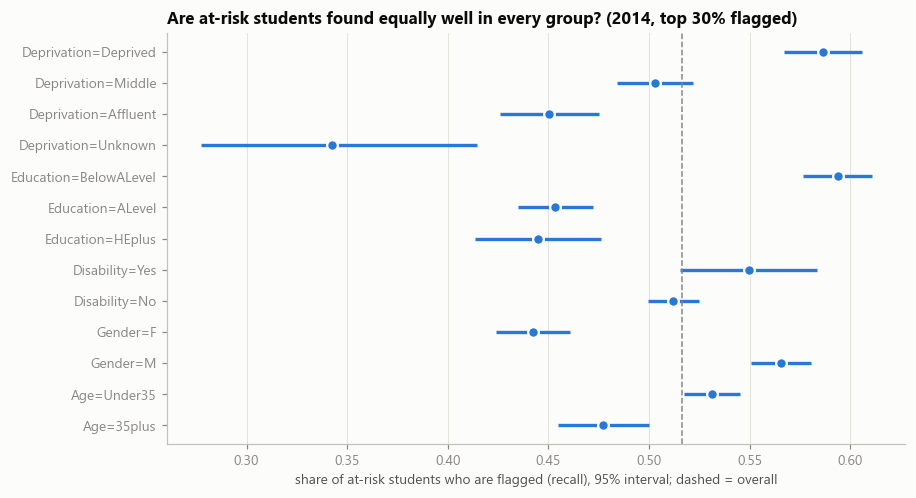

In [11]:
fig, ax = plt.subplots(figsize=(8.4, 4.6))
t = fair[fair.n >= 200].iloc[::-1]; y = np.arange(len(t))
ax.hlines(y, t.tpr_lo, t.tpr_hi, color=C1, linewidth=2.2); ax.plot(t.recall_TPR, y, "o", color=C1, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
overall_tpr = y_te[test._flag].sum() / y_te.sum(); ax.axvline(overall_tpr, color=MUTED, linestyle="--", linewidth=1)
ax.set_yticks(y, t.index); ax.grid(axis="y", visible=False); ax.set_xlabel("share of at-risk students who are flagged (recall), 95% interval; dashed = overall")
ax.set_title("Are at-risk students found equally well in every group? (2014, top 30% flagged)")
fig.tight_layout(); savefig(fig, "07a_fairness_recall.png"); plt.show()

## 4. Replication on 2014: engagement profiles and association rules

### 4.1 Risk by engagement profile (defined in notebook 05)

In [12]:
prof = cats_te["Profile"].values
rows = []
ptr = it.categories(train, clus, it.fit_item_spec(train))["Profile"].values
for n in ["NoActivity", "Low", "Intermittent", "Sustained"]:
    a, b = y_tr[ptr == n], y_te[prof == n]
    lo, hi = proportion_confint(b.sum(), len(b), method="wilson")
    rows.append(dict(profile=n, n_2013=len(a), rate_2013=a.mean(), n_2014=len(b), rate_2014=b.mean(), lo_2014=lo, hi_2014=hi, change=b.mean() - a.mean()))
prof_rep = pd.DataFrame(rows).set_index("profile"); prof_rep.to_csv(OUT / "profile_risk_2013_vs_2014.csv"); prof_rep

,n_2013,rate_2013,n_2014,rate_2014,lo_2014,hi_2014,change
profile,,,,,,,
NoActivity,457,0.807,483,0.834,0.799,0.865,0.027
Low,2914,0.627,3821,0.621,0.606,0.637,-0.006
Intermittent,3515,0.465,4890,0.473,0.459,0.487,0.009
Sustained,4932,0.288,6541,0.279,0.269,0.290,-0.008


**Observed.** The risk of each engagement profile is almost unchanged a year later: no activity 80.7% to 83.4% (2014 interval 79.9% to 86.5%), low 62.7% to 62.1%, intermittent 46.5% to 47.3%, sustained 28.8% to 27.9%. The order is the same and no change exceeds 3 points.

### 4.2 The 173 association rules from notebook 06, re-measured on 2014

In [13]:
rules = pd.read_csv(OUT / "association_rules_2013.csv")
ispec = json.loads((OUT / "item_spec.json").read_text())
items_te = it.to_items(cats_te); outc_te = it.outcome_items(test)
basket_te = pd.concat([items_te, outc_te], axis=1)
Nte = len(basket_te)
rows = []
for r in rules.itertuples():
    ante = r.antecedent_items.split("|")
    if any(a not in basket_te.columns for a in ante):
        rows.append(dict(rule=r.rule, consequent=r.consequent, n_2014=0)); continue
    m = basket_te[ante].all(axis=1).values; n = int(m.sum()); c = basket_te[r.consequent].values
    k = int((m & c).sum()); base = c.mean()
    lo, hi = proportion_confint(k, n, method="wilson") if n else (np.nan, np.nan)
    rows.append(dict(rule=r.rule, consequent=r.consequent, n_2013=r.n_antecedent, conf_2013=r.confidence, lift_2013=r.lift, n_2014=n, conf_2014=k / n if n else np.nan,
                     lo_2014=lo, hi_2014=hi, lift_2014=(k / n) / base if n else np.nan))
rep = pd.DataFrame(rows)
rep["inside_ci"] = (rep.conf_2013 >= rep.lo_2014) & (rep.conf_2013 <= rep.hi_2014)
rep["still_lift_125"] = rep.lift_2014 >= 1.25
rep["same_direction"] = rep.lift_2014 > 1.0
rep["conf_change"] = rep.conf_2014 - rep.conf_2013
rep.to_csv(OUT / "rules_replication_2014.csv", index=False)
v = rep.dropna(subset=["lift_2014"])
print(f"{len(rep)} rules; {len(v)} testable in 2014 (antecedent items exist)")
print(f"lift stays at 1.25 or above: {v.still_lift_125.mean():.1%} | lift above 1 (same direction): {v.same_direction.mean():.1%} | 2013 confidence inside the 2014 interval: {v.inside_ci.mean():.1%}")
print(f"mean confidence change: {v.conf_change.mean():+.3f} | mean absolute change: {v.conf_change.abs().mean():.3f} | Spearman correlation of lifts 2013 vs 2014: {stats.spearmanr(v.lift_2013, v.lift_2014)[0]:.3f}")
display(v.groupby("consequent").agg(rules=("rule", "size"), still_125=("still_lift_125", "mean"), inside_ci=("inside_ci", "mean"), mean_change=("conf_change", "mean")))

173 rules; 173 testable in 2014 (antecedent items exist)
lift stays at 1.25 or above: 83.8% | lift above 1 (same direction): 100.0% | 2013 confidence inside the 2014 interval: 50.3%
mean confidence change: -0.023 | mean absolute change: 0.038 | Spearman correlation of lifts 2013 vs 2014: 0.914


,rules,still_125,inside_ci,mean_change
consequent,,,,
Outcome=AtRisk,50,0.980,0.620,-0.021
Outcome=NotAtRisk,59,0.712,0.695,-0.013
Result=Distinction,8,0.875,0.125,0.069
Result=Fail,24,1.000,0.083,-0.058
Result=Pass,20,0.600,0.300,-0.070
Result=Withdrawn,12,0.917,0.500,0.012


Strongest at-risk rules from 2013 and their 2014 result:


,rule,n_2014,conf_2013,conf_2014,lo_2014,hi_2014,lift_2013,lift_2014
0,Deprivation=Deprived AND EarlyAssessment=MissedSome AND Education=BelowALevel,290,0.960,0.928,0.892,0.952,2.162,2.109
1,EarlyAssessment=MissedSome AND Profile=NoActivity,256,0.928,0.941,0.906,0.964,2.089,2.141
2,EarlyAssessment=MissedSome AND Education=BelowALevel,765,0.920,0.898,0.875,0.918,2.072,2.042
3,Deprivation=Deprived AND EarlyAssessment=MissedSome,562,0.909,0.895,0.867,0.918,2.048,2.035
4,EarlyAssessment=MissedSome,1676,0.876,0.851,0.833,0.867,1.972,1.935
5,Education=BelowALevel AND Module=DDD AND Profile=Low,255,0.834,0.773,0.717,0.820,1.878,1.757
6,Deprivation=Deprived AND Education=BelowALevel AND Profile=Low,594,0.811,0.734,0.697,0.768,1.827,1.669
7,Profile=NoActivity,483,0.807,0.834,0.799,0.865,1.818,1.897


Rules that did NOT replicate (lift under 1.25 in 2014): 28


,rule,consequent,n_2014,conf_2013,conf_2014,lift_2013,lift_2014
0,Deprivation=Unknown,Result=Pass,611,0.600,0.458,1.292,1.050
1,Deprivation=Affluent AND Load=Light AND Timing=Deadline,Result=Pass,1652,0.583,0.482,1.254,1.104
2,Age=Under35 AND Deprivation=Affluent AND EarlyScore=High,Result=Pass,647,0.601,0.493,1.292,1.130
3,Deprivation=Affluent AND EarlyAssessment=SubmittedAll AND Load=Light,Result=Pass,1927,0.588,0.495,1.265,1.134
4,EarlyAssessment=SubmittedAll AND Education=ALevel AND Load=Light,Outcome=NotAtRisk,3197,0.696,0.646,1.252,1.152
5,Education=HEplus AND Load=Light AND Profile=Sustained,Result=Pass,858,0.616,0.505,1.325,1.156
6,Deprivation=Affluent AND Education=ALevel AND Load=Light,Outcome=NotAtRisk,1276,0.702,0.652,1.262,1.164
7,EarlyScore=Mid AND Education=ALevel,Outcome=NotAtRisk,1385,0.697,0.653,1.254,1.166


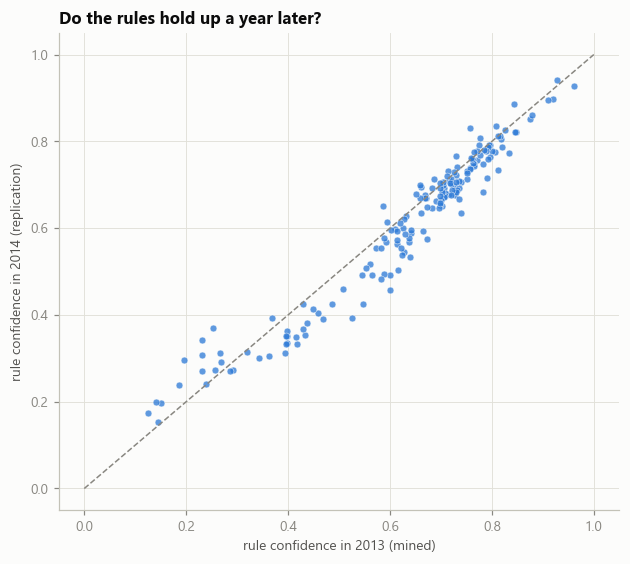

In [14]:
cols = ["rule", "n_2014", "conf_2013", "conf_2014", "lo_2014", "hi_2014", "lift_2013", "lift_2014"]
top = v[v.consequent == "Outcome=AtRisk"].sort_values("lift_2013", ascending=False).head(8)
print("Strongest at-risk rules from 2013 and their 2014 result:"); display(top[cols].reset_index(drop=True))
worst = v[v.lift_2014 < 1.25].sort_values("lift_2014").head(8)
print(f"Rules that did NOT replicate (lift under 1.25 in 2014): {len(v[v.lift_2014 < 1.25])}"); display(worst[["rule", "consequent", "n_2014", "conf_2013", "conf_2014", "lift_2013", "lift_2014"]].reset_index(drop=True))

fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.scatter(v.conf_2013, v.conf_2014, s=20, color=C1, alpha=0.75, edgecolors=SURFACE, linewidths=0.4); ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
ax.set_xlabel("rule confidence in 2013 (mined)"); ax.set_ylabel("rule confidence in 2014 (replication)"); ax.set_title("Do the rules hold up a year later?")
fig.tight_layout(); savefig(fig, "07a_rules_replication.png"); plt.show()

In [15]:
# The two support lists chosen in notebook 06 (precision floor 70% and 60%), measured on 2014
def list_perf(rule_names):
    flag = np.zeros(Nte, bool)
    for rn in rule_names: flag |= basket_te[rn.split(" AND ")].all(axis=1).values
    y_ = outc_te["Outcome=AtRisk"].values
    return dict(flagged_share=flag.mean(), precision=y_[flag].mean(), share_of_at_risk_reached=(y_ & flag).sum() / y_.sum())
lists = pd.DataFrame({"rule list at 70% precision floor (2013)": list_perf(ispec["support_list_rules_precision_70"]), "rule list at 60% precision floor (2013)": list_perf(ispec["support_list_rules_precision_60"])}).T
# compare with the model at the same flagged share
rows = []
for nm, r_ in lists.iterrows():
    k = r_.flagged_share; t_ = topk(y_te, test.p_primary.values, k); rows.append(dict(method=nm, flagged_share=k, precision_rule_list=r_.precision, reach_rule_list=r_.share_of_at_risk_reached, precision_model=t_["precision"], reach_model=t_["recall"]))
lists_cmp = pd.DataFrame(rows).set_index("method"); lists_cmp.to_csv(OUT / "rule_lists_vs_model_2014.csv"); lists_cmp

,flagged_share,precision_rule_list,reach_rule_list,precision_model,reach_model
method,,,,,
rule list at 70% precision floor (2013),0.302,0.691,0.475,0.756,0.519
rule list at 60% precision floor (2013),0.508,0.595,0.688,0.638,0.737


**Observed.** All 173 rules point the same way in 2014 (lift above 1) and **83.8% keep a lift of at least 1.25**; the lift rankings of 2013 and 2014 correlate at 0.91. Risk rules are the most stable: 49 of 50 at-risk rules (98%) and all 24 Fail rules keep their lift. The protective rules are weaker: 71% of the not-at-risk rules and 60% of the Pass rules keep a lift of 1.25 or more, and the 28 rules that do not replicate are mostly "light credit load" or "affluent" combinations.
Confidences are on average 2.3 points lower in 2014 (mean absolute change 3.8 points), the usual shrinkage for rules selected because they looked strongest; only half of the 2013 confidences fall inside the narrower 2014 intervals for that reason. The headline rule, a missed early assessment, goes from 87.6% to 85.1% (2014 interval 83.3% to 86.7%, 1,676 students); with a disadvantaged background from 96.0% to 92.8%.
**Rule lists against the model.** The 70%-precision list flags 30.2% of the students with 69.1% precision (71.4% in 2013) and reaches 47.5% of the at-risk students; the model at the same flagged share gets 75.6% and 51.9%. The 60% list flags 50.8% with 59.5% precision and reaches 68.8%, against 63.8% and 73.7% for the model.
**Why it matters.** The simple, transparent rules replicate well and give up only about 4 to 6 points of precision and reach compared with the model, a useful fallback when a model cannot be deployed.

## 5. How early can we predict? Cutoff sensitivity

The same day-28 students are scored with engagement-only features computed up to day 0 (before the start), 7, 14, 21 and 28, with the model trained on 2013 and tested on 2014. Using the same students at every cutoff keeps the comparison fair; a real deployment at an earlier cutoff would also include students who leave before day 28.

In [16]:
sv = pd.read_csv(RAW / "studentVle.csv", usecols=["code_module", "code_presentation", "id_student", "date", "sum_click"],
                 dtype={"code_module": "category", "code_presentation": "category", "id_student": "int32", "date": "int16", "sum_click": "int16"})
sv = sv[sv["date"] < 28].astype({"code_module": "object", "code_presentation": "object"})
MPK = ["code_module", "code_presentation"]
CUTS = [0, 7, 14, 21, 28]
frames = []
for c in CUTS:
    w = sv[sv["date"] < c]
    agg = w.groupby(KEY).agg(clicks=("sum_click", "sum"), days=("date", "nunique")).reset_index()
    f = feat[KEY + ["split", "target_at_risk"]].merge(agg, on=KEY, how="left").fillna({"clicks": 0, "days": 0})
    f["log_clicks"] = np.log1p(f.clicks); f["no_activity"] = (f.clicks == 0).astype(int)
    g = f.groupby(MPK)
    f["pct_clicks"] = g.clicks.rank(pct=True); f["pct_days"] = g.days.rank(pct=True)
    f["cutoff"] = c; frames.append(f)
cut = pd.concat(frames, ignore_index=True)
ECOLS = ["log_clicks", "days", "no_activity", "pct_clicks", "pct_days"]
rows = []
for c in CUTS:
    d = cut[cut.cutoff == c]; a, b = d[d.split == "train"], d[d.split == "test"]
    for kind, p in (("logit", dict(C=1.0)), ("hgb", best_h.params)):
        m = make_pipe(ECOLS, [], kind, **p).fit(a[ECOLS], a.target_at_risk); pr = m.predict_proba(b[ECOLS])[:, 1]
        rows.append(dict(cutoff_day=c, model=kind, auc=roc_auc_score(b.target_at_risk, pr), pr_auc=average_precision_score(b.target_at_risk, pr)))
cutres = pd.DataFrame(rows).pivot(index="cutoff_day", columns="model", values=["auc", "pr_auc"])
cutres.columns = [f"{a}_{b}" for a, b in cutres.columns]
cutres["full_model_day28_auc"] = roc_auc_score(y_te, test.p_primary)
cutres.to_csv(OUT / "cutoff_sensitivity_2014.csv"); cutres

,auc_hgb,auc_logit,pr_auc_hgb,pr_auc_logit,full_model_day28_auc
cutoff_day,,,,,
0,0.637,0.641,0.565,0.567,0.780
7,0.665,0.667,0.594,0.601,0.780
14,0.679,0.681,0.620,0.621,0.780
21,0.689,0.688,0.642,0.637,0.780
28,0.697,0.697,0.651,0.651,0.780


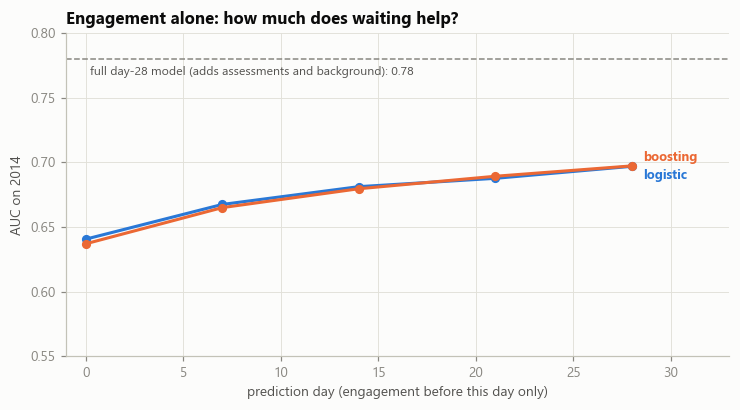

In [17]:
fig, ax = plt.subplots(figsize=(6.8, 3.8))
ax.plot(cutres.index, cutres.auc_logit, "-o", color=C1, linewidth=2, markersize=5); ax.plot(cutres.index, cutres.auc_hgb, "-o", color=C2, linewidth=2, markersize=5)
full_auc = roc_auc_score(y_te, test.p_primary)
ax.axhline(full_auc, color=MUTED, linestyle="--", linewidth=1); ax.text(0.2, full_auc - 0.012, "full day-28 model (adds assessments and background): %.2f" % full_auc, color=INK2, fontsize=8)
ax.text(28.6, cutres.auc_logit.iloc[-1] - 0.007, "logistic", color=C1, fontsize=8.5, va="center", fontweight="bold"); ax.text(28.6, cutres.auc_hgb.iloc[-1] + 0.007, "boosting", color=C2, fontsize=8.5, va="center", fontweight="bold")
ax.set_xlim(-1, 33); ax.set_ylim(0.55, 0.80); ax.set_xlabel("prediction day (engagement before this day only)"); ax.set_ylabel("AUC on 2014")
ax.set_title("Engagement alone: how much does waiting help?")
fig.tight_layout(); savefig(fig, "07a_cutoff_sensitivity.png"); plt.show()

**Observed.** Engagement alone gives an AUC of 0.64 before the course starts (clicks on the days before day 0), 0.67 at day 7, 0.68 at day 14, 0.69 at day 21 and 0.70 at day 28. Most of the gain from waiting comes in the first two weeks; the second fortnight adds about 0.02. The full day-28 model reaches 0.78, so early assessment behaviour and background add about 0.08 on top of engagement.
**Why it matters.** Useful warning signals exist even before the course starts, and a two-week checkpoint captures most of what engagement can offer. Assessment behaviour is what makes the day-28 model good, so it cannot be moved earlier than the first deadline.
**Caveat.** The same students are scored at every cutoff; a real earlier deployment would also include students who leave before day 28.

## 6. Save predictions

In [18]:
test[KEY + ["target_at_risk", "target_final_result", "p_logit", "p_hgb", "p_inter", "p_primary", "p_nosens"]].to_csv(PROC / "oulad_predictions_2014.csv", index=False)
json.dump({"primary": PRIMARY, "logit_params": best_l.params, "hgb_params": best_h.params, "selected_numeric": SEL_NUM, "selected_categorical": SEL_CAT,
           "flag_policy": "top 30% of predicted risk", "cv_auc": {"logit": float(best_l.cv_auc), "hgb": float(best_h.cv_auc), "interaction": float(int_a.mean())}},
          open(OUT / "final_model_spec.json", "w"), indent=2)
print("saved predictions and the final model spec")

saved predictions and the final model spec


## 7. Synthesis and decision

**How good is the model, honestly?** On a year it has never seen it ranks students with an AUC of 0.78 (interval 0.77 to 0.79), is well calibrated, and when the top 30% are flagged three in four of them are at risk and half of all at-risk students are found. That is a clear improvement over any single signal (0.70 at best) and replicates the cross-validated estimate to within 0.013. It is a useful triage tool, not a crystal ball: half of the at-risk students are missed at that flagging level.

**Where it works less well.** GGG (AUC 0.69) and the small module AAA; students with a disability, whose risk is under-predicted by about 5 points; and, by construction, students with no early assessment evidence.

**Fairness.** With the socio-economic features the model finds more of the disadvantaged students that are at risk but also flags twice as many of those who are not. Without them, error rates are almost equal across deprivation and education groups at a cost of 0.009 AUC. The recommended design is to drop them from the alert model and use them only for human decisions about support. The apparent gender gap is a module-mix effect.

**Replication.** Engagement-profile risks and 84% of the association rules hold in 2014 with small shrinkage; risk rules replicate better than protective ones.

**Decision.** The data and the model are fit for an *early-warning triage* use. Proceed, provided that (1) alerts trigger supportive contact, not penalties, (2) the alert model excludes the socio-economic features, (3) per-module monitoring is in place (07b), and (4) the effect of the contact is tested in a controlled trial (07c).